# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## Grupo: Triangulados

# Integrantes
* Lucila Posse
* Milena Ventroni
* Pilar Larriera
* Francisco Krause Arnim 


### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 8.


#### Solución

Para que el sistema homogéneo $Qm=0$ tenga una solución no nula única salvo un factor de escala, es necesario que el núcleo de $Q$ tenga dimensión 1. Por el teorema de rango-nulidad, dado que $Q$ tiene 12 columnas:

$$
\operatorname{rg}(Q)+\dim(\ker Q)=12
$$

Por lo tanto su rango debe ser exactamente 11.

Como cada correspondencia entre un punto 3D y su proyección 2D aporta dos filas a $Q$, se necesitan como mínimo 6 puntos:

$$
2n\geq11\implies n\geq6
$$

Sin embargo, no cualquier conjunto de 6 puntos es suficiente: deben encontrarse posicionados de una manera tal que la matriz $Q$ resultante tenga rango 11. En particular, <u>los puntos no pueden ser todos coplanares</u>.

**Justificación de la no coplanaridad**

Si todos los puntos 3D son coplanares, existe un vector no nulo $a\in\mathbb{R}^4$ tal que:

$$
a^TP_i=0 \qquad \forall i
$$

donde $P_i=(U_i,V_i,W_i,1)^T$.

Recordando que cada punto aporta dos filas a $Q$:

$$
Q_i=
\begin{pmatrix}
P_i^T & 0^T & -u_iP_i^T\\
0^T & P_i^T & -v_iP_i^T
\end{pmatrix}
$$

Como $a^TP_i=0$, los siguientes vectores pertenecen al núcleo de $Q$:

$$
m_1=
\begin{pmatrix}a\\0\\0\end{pmatrix},
\qquad
m_2=
\begin{pmatrix}0\\a\\0\end{pmatrix},
\qquad
m_3=
\begin{pmatrix}0\\0\\a\end{pmatrix}
$$

Estos tres vectores son linealmente independientes, ya que $a\neq0$ y está en filas distintas en cada uno.

Además, el vector $m$ correspondiente a la matriz de proyección de la cámara también pertenece al núcleo de $Q$. Como dicha matriz representa una cámara válida, no puede tener todas sus filas proporcionales a $a^T$, por lo que $m$ es linealmente independiente de $m_1,m_2,m_3$.

Entonces:

$$
\dim(\ker Q)\geq4
$$

Por rango-nulidad:

$$
\operatorname{rg}(Q)=12-\dim(\ker Q)\leq8
$$

Por lo tanto, si todos los puntos son coplanares, $Q$ no puede alcanzar rango 11. Esto demuestra que los puntos no pueden ser todos coplanares para determinar una única matriz de proyección salvo escala.

##### Minimización

Buscamos el vector $m$ que resuelve:

$$
\min_{\|m\|_2=1}m^TQ^TQm
=
\min_{\|m\|_2=1}\|Qm\|_2^2
$$



Luego, usamos la descomposición en valores singulares de $Q$, siguiendo lo visto en el item 1a, $Q\in\mathbb{R}^{12\times12}$:

$$
Q=U\Sigma V^T
$$

Entonces:

$$
\begin{aligned}
Q^TQ
&=(V\Sigma^TU^T)(U\Sigma V^T)\\
&=V\Sigma^2V^T
\end{aligned}
$$

donde utilizamos que $U^TU=I$ y que $\Sigma$ es diagonal, por lo que $\Sigma^T=\Sigma$.

Como $\Sigma^2$ es una matriz diagonal cuyos elementos son los cuadrados de los valores singulares, reemplazamos en la expresión a minimizar:

$$
\min_{\|m\|_2=1}m^TV\Sigma^2V^Tm
$$

Realizamos el cambio de variable:

$$
y^T=m^TV
\quad\Longrightarrow\quad
y=V^Tm
$$

Como $V$ es ortogonal:

$$
\|y\|_2^2=y^Ty=m^TVV^Tm=m^Tm=1
$$

De esta manera, el problema queda:

$$
\min_{\|y\|_2=1}y^T\Sigma^2y
$$

Considerando los valores singulares ordenados de mayor a menor:

$$
\sigma_1\geq\sigma_2\geq\cdots\geq\sigma_{12}\geq0
$$

Tenemos:

$$
\begin{aligned}
y^T\Sigma^2y
&=\sum_{i=1}^{12}\sigma_i^2y_i^2\\
&\geq\sigma_{12}^2\sum_{i=1}^{12}y_i^2\\
&=\sigma_{12}^2\|y\|_2^2\\
&=\sigma_{12}^2
\end{aligned}
$$

Por lo tanto:

$$
m^TQ^TQm\geq\sigma_{12}^2
$$

Para alcanzar esta cota inferior, tomamos:

$$
y=e_{12}=(0,\ldots,0,1)^T
$$

Este vector cumple $\|y\|_2=1$ y:

$$
y^T\Sigma^2y=\sigma_{12}^2
$$

Como $y=V^Tm$, recuperamos:

$$
m=Vy=Ve_{12}=v_{12}
$$

Es decir, $m$ es la última columna de $V$, asociada al menor valor singular de $Q$.

Por lo tanto:

$$
\boxed{
\min_{\|m\|_2=1}m^TQ^TQm=\sigma_{12}^2
}
$$

Y una solución es:

$$
\boxed{m=v_{12}}
$$

ya que los autovalores de $Q^TQ$ son los cuadrados de los valores singulares de $Q$:

$$
\boxed{
\lambda_{\min}(Q^TQ)=\sigma_{12}^2
}
$$

Entonces, el vector $m$ es un autovector unitario asociado al menor autovalor de $Q^TQ$, o equivalentemente la última columna de $V$ en la descomposición SVD de $Q$.


### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



#### Solución
##### Cálculo de R,t y K

Para recuperar los parámetros intrínsecos y extrínsecos de la cámara, partimos de las correspondencias entre los puntos del mundo real y sus proyecciones en la imagen.

En primer lugar, construimos la matriz $Q$ mediante la función `obtenerQ3d`, siguiendo la ecuación (6) del enunciado.

Cada correspondencia aporta dos filas:

$$
Q_i=
\begin{pmatrix}
P_i^T & 0^T & -u_iP_i^T\\
0^T & P_i^T & -v_iP_i^T
\end{pmatrix},
$$

donde $P_i=(U_i,V_i,W_i,1)^T$.

Para la primera captura contamos con 12 correspondencias, por lo que:

$$
Q\in\mathbb{R}^{24\times12}.
$$

Comenzamos con la implementación de la siguiente manera:

In [ ]:
# Hacemos todos los imports que necesitamos para LA TOTALIDAD del tp
import numpy as np
import os
import alc as alc
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Ejercicio 2.a - Calibración con puntos 3D

# 1. Cargamos los datos
ruta_puntos_3d = os.path.join("calib", "3d", "p_W_corners.txt")
ruta_puntos_2d = os.path.join("calib", "3d", "detected_corners.txt")

objPts_3d = np.loadtxt(ruta_puntos_3d, delimiter=",")
datos_3d = np.loadtxt(ruta_puntos_2d)

# Utilizamos la primera captura
imgPts_3d = datos_3d[0].reshape(12, 2)

# 2. Construimos la matriz Q
Q_3d = alc.obtenerQ3d(imgPts_3d, objPts_3d)

np.set_printoptions(threshold=50, precision=2, suppress=True)

print("Dimensiones de Q:", Q_3d.shape)
print("\nMatriz Q (resumida):")
print(Q_3d)

Dimensiones de Q: (24, 12)

Matriz Q (resumida):
[[     0.        8.        0.   ...  -1492.       -0.     -186.5 ]
 [     0.        0.        0.   ...  -1500.       -0.     -187.5 ]
 [    10.4       8.        0.   ...  -2116.       -0.     -264.5 ]
 ...
 [     0.        0.        0.   ...  -7012.5    3071.47   -280.5 ]
 [    19.4      25.      -24.45 ... -12412.5   12139.42   -496.5 ]
 [     0.        0.        0.   ...  -7512.5    7347.22   -300.5 ]]


Luego, recuperamos la matriz de proyección $M$ mediante la función `resolverDLT3D`. Como vimos en el ejercicio 1.b, el vector unitario que minimiza $\|Qm\|_2^2$ es un autovector asociado al menor autovalor de $Q^TQ$.

In [226]:
# 3. Recuperamos la matriz de proyección M
M_3d = alc.resolverDLT3D(Q_3d)

print("\nDimensiones de M:", M_3d.shape)
print("\nMatriz de proyección M:")
print(M_3d)


Dimensiones de M: (3, 4)

Matriz de proyección M:
[[-0.06 -0.02  0.01 -0.84]
 [-0.   -0.06 -0.01 -0.54]
 [-0.   -0.   -0.   -0.01]]


Finalmente, buscamos descomponer la matriz de proyección como:

$$
M\sim K[R\mid t],
$$

donde $K$ contiene los parámetros intrínsecos, $R$ es la matriz de rotación y $t$ es el vector de traslación.

Como $M$ está determinada salvo un factor de escala, la normalizamos antes de aplicar `devolverMatricesCalibracion3d`. Esta función utiliza una factorización QR para recuperar los parámetros de calibración.


In [227]:
# 4. Normalizamos M para recuperar K, R y t
escala_3d = alc.norma(M_3d[2, :3], 2)
M_normalizada = M_3d / escala_3d

R_3d, t_3d, K_3d = alc.devolverMatricesCalibracion3d(M_normalizada)

print("\nMatriz K:")
print(K_3d)

print("\nMatriz R:")
print(R_3d)

print("\nVector t:")
print(t_3d)



Matriz K:
[[425.86  -0.02 354.42]
 [  0.   424.57 256.85]
 [  0.     0.     1.  ]]

Matriz R:
[[ 0.62  0.13 -0.78]
 [-0.36  0.93 -0.13]
 [ 0.7   0.35  0.62]]

Vector t:
[-18.17 -14.5   40.59]


Para verificar nuestros resultados comprobamos que:

$$
R^TR\approx I,
\qquad
\det(R)\approx1.
$$

In [228]:

# 5. Verificamos que R sea una matriz de rotación
RtR_3d = alc.multiplicacion_matrices(
    alc.transpuesta(R_3d), R_3d
)

print("\nR^T R:")
print(RtR_3d)

det_R = (
    R_3d[0, 0] * (R_3d[1, 1]*R_3d[2, 2] - R_3d[1, 2]*R_3d[2, 1])
    - R_3d[0, 1] * (R_3d[1, 0]*R_3d[2, 2] - R_3d[1, 2]*R_3d[2, 0])
    + R_3d[0, 2] * (R_3d[1, 0]*R_3d[2, 1] - R_3d[1, 1]*R_3d[2, 0])
)

print("\nDeterminante de R:", det_R)


R^T R:
[[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]

Determinante de R: 1.0


##### Cálculo de nuevo set de parámetros: $\alpha_u = \alpha_v$ 

Luego, como pide la consigna, buscamos recuperar un nuevo conjunto de parámetros imponiendo que los factores de escala de la matriz intrínseca sean iguales:

$$
\alpha_u=\alpha_v.
$$

Para hacerlo, usamos el parámetro opcional `restric="alfa"` de la función `devolverMatricesCalibracion3d`.

La implementación toma el promedio de los factores de escala obtenidos inicialmente e impone ese valor para ambos. A continuación, recalcula los parámetros extrínsecos y ortonormaliza la matriz de rotación.

Como estamos imponiendo una restricción adicional, la descomposición resultante puede aproximar la matriz de proyección original.

In [229]:
# Ejercicio 2.b - Restricción alfa_u = alfa_v

R_alfa, t_alfa, K_alfa = alc.devolverMatricesCalibracion3d(
    M_normalizada, restric="alfa"
)

print("Matriz K:")
print(K_alfa)

print("\nMatriz R:")
print(R_alfa)

print("\nVector t:")
print(t_alfa)

# Verificamos la restricción
print("\nAlfa_u:", K_alfa[0, 0])
print("Alfa_v:", K_alfa[1, 1])
print("Diferencia:", K_alfa[0, 0] - K_alfa[1, 1])


Matriz K:
[[425.21  -0.02 354.42]
 [  0.   425.21 256.85]
 [  0.     0.     1.  ]]

Matriz R:
[[ 0.62  0.13 -0.78]
 [-0.36  0.93 -0.13]
 [ 0.7   0.35  0.62]]

Vector t:
[-18.2  -14.48  40.59]

Alfa_u: 425.2125839801633
Alfa_v: 425.2125839801633
Diferencia: 0.0


##### Cálculo nuevo set de parámetros: $K_{12}=0$

Además, la consigna pide recuperar un nuevo conjunto de parámetros imponiendo que el parámetro de oblicuidad (*skew*) sea nulo:

$$
K_{12}=0.
$$

Para resolver esto usamos el parámetro opcional `restric="skew"` de la función `devolverMatricesCalibracion3d`.

Esta restricción considerara que los ejes de la grilla de píxeles son perpendiculares.

La implementación modifica la matriz de parámetros intrínsecos y recalcula los parámetros extrínsecos correspondientes, ortonormalizando nuevamente la matriz de rotación.

In [230]:
# Ejercicio 2.c - Restricción K_12 = 0

R_skew, t_skew, K_skew = alc.devolverMatricesCalibracion3d(M_normalizada, restric="skew")

print("Matriz K:")
print(K_skew)

print("\nMatriz R:")
print(R_skew)

print("\nVector t:")
print(t_skew)

# Verificamos la restricción
print("\nParámetro skew:", K_skew[0, 1])


Matriz K:
[[425.86   0.   354.42]
 [  0.   424.57 256.85]
 [  0.     0.     1.  ]]

Matriz R:
[[ 0.62  0.13 -0.78]
 [-0.36  0.93 -0.13]
 [ 0.7   0.35  0.62]]

Vector t:
[-18.17 -14.5   40.59]

Parámetro skew: 0.0


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

#### Solución
##### Matriz K
Para obtener la matriz de parámetros intrínsecos $K$, utilizamos el método de calibración con puntos coplanares.

El tablero contiene 77 esquinas internas, distribuidas en 11 columnas y 7 filas, separadas por 30 mm. Como todos los puntos pertenecen a un mismo plano, consideramos sus coordenadas $(U,V)$, tomando $W=0$.

Para cada imagen, construimos una matriz $Q_j$ a partir de las correspondencias entre los puntos del tablero y sus proyecciones. Cada correspondencia aporta dos ecuaciones, por lo que:

$$
Q_j\in\mathbb{R}^{154\times9}.
$$

Luego, mediante la función `resolverDLT2D`, obtenemos la homografía $H_j$ asociada a cada vista, que relaciona las coordenadas del tablero con las coordenadas de la imagen:

$$
\lambda
\begin{pmatrix}
u\\v\\1
\end{pmatrix}
=
H_j
\begin{pmatrix}
U\\V\\1
\end{pmatrix}.
$$

In [231]:
# Cargamos las coordenadas de las esquinas
ruta_coplanar = os.path.join("calib", "coplanar", "marcadas")
ruta_esquinas = os.path.join(ruta_coplanar, "esquinas.csv")

esquinas = pd.read_csv(ruta_esquinas)

# Path de imágenes + sanity check de que sean 20
imagenes = [file for file in os.listdir(ruta_coplanar) if file.endswith(".png")]
assert(len(imagenes) == 20)


# Construimos Q y calculamos H para cada imagen
matrices_Q = {}
matrices_H = {}
Hlist = []


for imagen in imagenes:
    # Seleccionamos las correspondencias de la imagen
    datos_img = esquinas[esquinas["imagen"] == imagen]

    objPts = np.asarray(datos_img[["U", "V"]])
    imgPts = np.asarray(datos_img[["u", "v"]])

    # Construimos Q
    Q = alc.obtenerQ2d(imgPts, objPts)
    matrices_Q[imagen] = Q

    # Recuperamos la homografía
    H = alc.resolverDLT2D(Q)
    matrices_H[imagen] = H
    Hlist.append(H)

    print(f"{imagen}: Q {Q.shape}, H {H.shape}")

Im_R_1.png: Q (154, 9), H (3, 3)
Im_R_10.png: Q (154, 9), H (3, 3)
Im_R_11.png: Q (154, 9), H (3, 3)
Im_R_12.png: Q (154, 9), H (3, 3)
Im_R_13.png: Q (154, 9), H (3, 3)
Im_R_14.png: Q (154, 9), H (3, 3)
Im_R_15.png: Q (154, 9), H (3, 3)
Im_R_16.png: Q (154, 9), H (3, 3)
Im_R_17.png: Q (154, 9), H (3, 3)
Im_R_18.png: Q (154, 9), H (3, 3)
Im_R_19.png: Q (154, 9), H (3, 3)
Im_R_2.png: Q (154, 9), H (3, 3)
Im_R_20.png: Q (154, 9), H (3, 3)
Im_R_3.png: Q (154, 9), H (3, 3)
Im_R_4.png: Q (154, 9), H (3, 3)
Im_R_5.png: Q (154, 9), H (3, 3)
Im_R_6.png: Q (154, 9), H (3, 3)
Im_R_7.png: Q (154, 9), H (3, 3)
Im_R_8.png: Q (154, 9), H (3, 3)
Im_R_9.png: Q (154, 9), H (3, 3)


A partir de las homografías, construimos la matriz $A$ mediante la función `armarA`.

In [232]:
# Construimos la matriz A
A = alc.armarA(Hlist)

print("\nCantidad de homografías:", len(Hlist))
print("Dimensiones de A:", A.shape)


Cantidad de homografías: 20
Dimensiones de A: (40, 6)


Finalmente, recuperamos la matriz de parámetris intrínsecos usando `calcularMatrizK2D`:
$$
K=
\begin{pmatrix}
\alpha_u & s & u_0\\
0 & \alpha_v & v_0\\
0 & 0 & 1
\end{pmatrix}.
$$


In [233]:
# Calculamos la matriz K
K = alc.calcularMatrizK2D(A)

print("\nMatriz de parámetros intrínsecos K:")
print(K)



Matriz de parámetros intrínsecos K:
[[745.22  -1.   519.5 ]
 [  0.   756.53 298.49]
 [  0.     0.     1.  ]]


##### Recuperación de la pose

Como ya fue obtenida la matriz de calibración intrínseca $K$, podemos recuperar la pose de la cámara para cada una de las vistas solicitadas en la consigna.

Notamos que los puntos utilizados pertenecen a un mismo plano, la homografía $H$ entre las coordenadas del plano y las coordenadas de la imagen se relaciona con los parámetros de la cámara mediante:

$$
H \sim K
\begin{pmatrix}
| & | & | \\
r_1 & r_2 & t \\
| & | & |
\end{pmatrix},
$$

donde $r_1$ y $r_2$ son las dos primeras columnas de la matriz de rotación $R$, y $t$ es el vector de traslación. Por lo tanto, conociendo $H$ y $K$, podemos recuperar ambos parámetros mediante la función `obtenerPose2D`.

Aplicamos este procedimiento a las imágenes `Im_R_1.png`, `Im_R_10.png` e `Im_R_20.png` como fue pedido y además, para comprobar que la matriz obtenida es una rotación válida, verificamos las siguientes propiedades:

$$
R^T R \approx I
$$

$$
\det(R)\approx 1.
$$

La primera condición comprueba la ortogonalidad de la matriz, mientras que la segunda permite verificar que se trata de una rotación propia y no de una reflexión.

In [234]:
# Ejercicio 3.b - Recuperar la pose de las vistas solicitadas
poses = {}
imagenes_solicitadas = ["Im_R_1.png", "Im_R_10.png", "Im_R_20.png"]

for imagen in imagenes_solicitadas:

    # Recuperamos la pose
    H = matrices_H[imagen]
    R, t = alc.obtenerPose2D(H, K)

    poses[imagen] = (R, t)

    print(f"\n--- {imagen} ---")

    print("Matriz R:")
    print(R)

    print("\nVector t:")
    print(t)

    # Verificamos ortogonalidad
    RtR = alc.multiplicacion_matrices(alc.transpuesta(R), R)

    print("\nR^T R:")
    print(RtR)

    # Determinante de R (fórmula para matrices 3x3)
    det_R = (R[0, 0] * (R[1, 1]*R[2, 2] - R[1, 2]*R[2, 1])
            - R[0, 1] * (R[1, 0]*R[2, 2] - R[1, 2]*R[2, 0])
            + R[0, 2] * (R[1, 0]*R[2, 1] - R[1, 1]*R[2, 0]))

    print("\nDeterminante de R:", det_R)



--- Im_R_1.png ---
Matriz R:
[[ 1.   -0.01 -0.03]
 [ 0.01  1.    0.01]
 [ 0.03 -0.01  1.  ]]

Vector t:
[-108.62 -141.28  550.36]

R^T R:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

Determinante de R: 1.0

--- Im_R_10.png ---
Matriz R:
[[ 1.    0.07 -0.02]
 [-0.06  0.99  0.16]
 [ 0.04 -0.16  0.99]]

Vector t:
[ -95.83 -153.93  541.17]

R^T R:
[[ 1. -0.  0.]
 [-0.  1.  0.]
 [ 0.  0.  1.]]

Determinante de R: 1.0000000000000002

--- Im_R_20.png ---
Matriz R:
[[ 0.99  0.03 -0.14]
 [-0.04  1.   -0.08]
 [ 0.14  0.09  0.99]]

Vector t:
[ -83.23 -146.3   489.27]

R^T R:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

Determinante de R: 1.0


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la cancha de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

#### Solución
##### Análisis del gol de Enzo

Una cancha de fútbol es un plano, por lo tanto podemos relacionar sus coordenadas métricas $(U,V)$ con las coordenadas de los píxeles $(u,v)$ mediante una homografía $H$.

Para estimarla, seleccionamos siete puntos de referencia cuyas posiciones conocemos tanto en la cancha como en la imagen. A partir de estas correspondencias construimos la matriz $Q$ y recuperamos $H$ mediante DLT.

La transformación entre ambos sistemas queda expresada como:

$$
\lambda
\begin{pmatrix}
u\\v\\1
\end{pmatrix}
=
H
\begin{pmatrix}
U\\V\\1
\end{pmatrix}.
$$

In [235]:
# Ejercicio 4.a - Homografía y distancia de Enzo

# Coordenadas de los puntos de referencia en la cancha (metros)
objPts_gol = np.array([[0, 24.84], [0, 43.16], [5.5, 24.84], [5.5, 43.16], [16.5, 26.69], [16.5, 41.31], [20.15, 34]], dtype=float)

# Correspondencias en la imagen (píxeles)
imgPts_gol = np.array([[191, 171], [843, 189], [153, 231], [867, 251], [144, 405], [853, 422], [506, 488]], dtype=float)

# Construimos Q y recuperamos la homografía
Q_gol = alc.obtenerQ2d(imgPts_gol, objPts_gol)
H_gol = alc.resolverDLT2D(Q_gol)

# Normalizamos H para facilitar su lectura
H_gol = H_gol / H_gol[2, 2]

print("Homografía H:")
print(H_gol)

# Verificamos la reproyección de los puntos de referencia
rep_gol = alc.cancha_a_imagen(H_gol, objPts_gol)
error_gol = np.max(np.abs(rep_gol - imgPts_gol))

print("\nError máximo de reproyección (píxeles):", error_gol)

Homografía H:
[[  -9.87   39.8  -786.42]
 [   8.1     1.68  137.76]
 [  -0.02    0.      1.  ]]

Error máximo de reproyección (píxeles): 3.390643338215739



Una vez obtenida la homografía, utilizamos su inversa para recuperar la posición de los pies de Enzo en coordenadas de la cancha:

$$
\begin{pmatrix}
U_E\\V_E\\1
\end{pmatrix}
\sim
H^{-1}
\begin{pmatrix}
u_E\\v_E\\1
\end{pmatrix}.
$$


In [236]:
# Posición de los pies de Enzo en la imagen
pie_enzo = np.array([[808, 541]], dtype=float)

# Transformamos la posición a coordenadas de cancha
UV_enzo = alc.imagen_a_cancha(H_gol, pie_enzo)

Tomamos como origen del sistema de coordenadas el arco izquierdo, por lo que su línea de gol está definida por lo que su línea de gol está definida por $U=0$. En consecuencia, la distancia perpendicular de Enzo a dicha línea es:

$$
\boxed{d=|U_E|}
$$
```

In [237]:
# Distancia a la línea de gol U = 0
distancia_enzo = np.abs(UV_enzo[0, 0])

print("\nPosición de Enzo en la cancha (m):", UV_enzo)
print("Distancia de Enzo a la línea de gol (m):", distancia_enzo)


Posición de Enzo en la cancha (m): [[22.21 39.67]]
Distancia de Enzo a la línea de gol (m): 22.205979053760014


Una vez obtenida la homografía, podemos ubicar a los jugadores argentinos sobre el plano de la cancha transformando las coordenadas de sus pies mediante $H^{-1}$.

Para cada jugador, definimos un círculo de radio un metro en coordenadas de cancha, centrado en su posición $(U_0,V_0)$:

$$
(U-U_0)^2+(V-V_0)^2=1.
$$

Generamos puntos pertenecientes a cada circunferencia y los proyectamos sobre la fotografía mediante $H$.

Debido a la perspectiva de la cámara, las circunferencias no necesariamente se ven como círculos en la imagen, sino que pueden aparecer deformadas.

###### Observación: Durante la implementación de esta consigna nos dimos cuenta que el enunciado de la nb y el pdf no coinciden. La nb pide circunferencias de 1 metro de diametro mientras que el pdf de 1 metro de radio. Como descubrimos esto de último momento no llegamos a consultarlo, dejamos la implementación que sigue el enunciado original. 

Posiciones de los jugadores argentinos (metros):
Jugador 1 : [22.21 39.67]
Jugador 2 : [22.33 27.13]
Jugador 3 : [15.97 28.59]
Jugador 4 : [11.76 30.88]
Jugador 5 : [12.67 41.77]
Jugador 6 : [ 9.51 31.06]


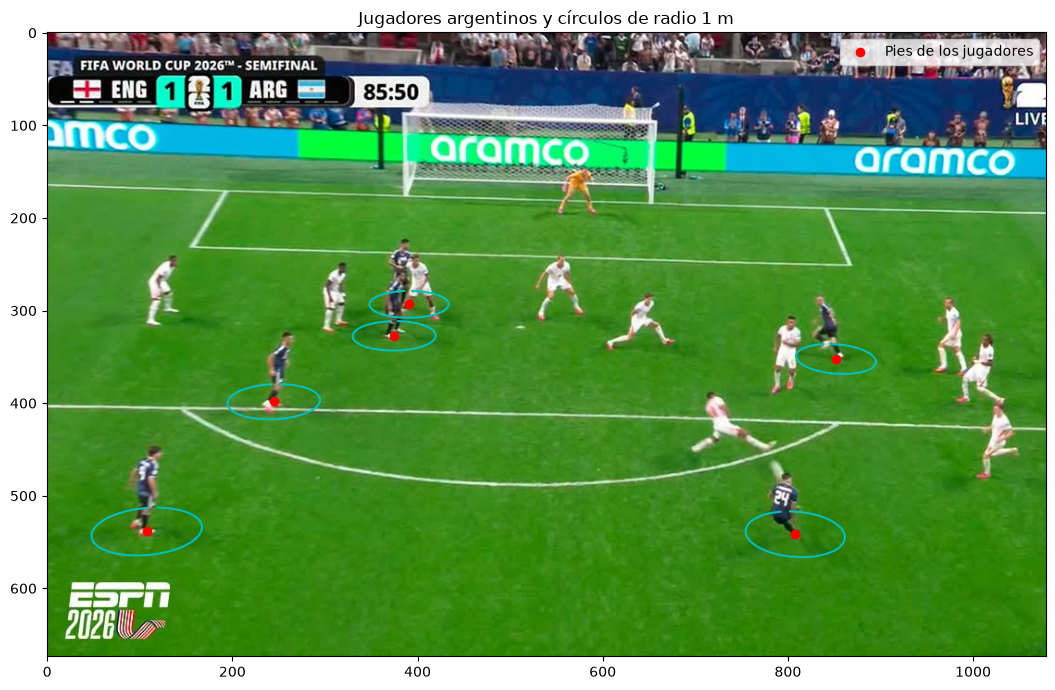

In [238]:
# Posiciones de los pies de los jugadores argentinos en píxeles
pies_arg = np.array([[808, 541], [108, 538], [245, 398], [375, 327], [852, 352],  [391, 293]], dtype=float)

# Transformamos los pies a coordenadas de cancha
UV_arg = alc.imagen_a_cancha(H_gol, pies_arg)

print("Posiciones de los jugadores argentinos (metros):")
for i in range(len(UV_arg)):
    print("Jugador", i + 1, ":", UV_arg[i])

# Generamos los valores de la semicircunferencia superior
x_circ = np.hstack((
    np.arange(-1.0, 1.0, 0.02),
    np.array([1.0])
))

n_circ = len(x_circ)

# Cargamos la fotografía original
ruta_gol = os.path.join("futbol", "test-gol-enzo.png")
img_gol = mpimg.imread(ruta_gol)

plt.figure(figsize=(12, 7))
plt.imshow(img_gol)

# Construimos y proyectamos un círculo para cada jugador
for i in range(len(UV_arg)):

    UV0 = UV_arg[i]

    circ = np.zeros((2 * n_circ - 2, 2))

    # Semicircunferencia superior
    for k in range(n_circ):
        circ[k, 0] = UV0[0] + x_circ[k]
        circ[k, 1] = UV0[1] + np.sqrt(1.0 - x_circ[k]**2)

    # Semicircunferencia inferior
    for k in range(1, n_circ - 1):
        x = x_circ[n_circ - 1 - k]
        j = n_circ + k - 1

        circ[j, 0] = UV0[0] + x
        circ[j, 1] = UV0[1] - np.sqrt(1.0 - x**2)

    # Proyectamos los puntos del círculo a la imagen
    circ_img = alc.cancha_a_imagen(H_gol, circ)

    plt.plot(circ_img[:, 0], circ_img[:, 1], 'c')

# Marcamos los centros de los círculos
plt.scatter(pies_arg[:, 0], pies_arg[:, 1], color='red', label='Pies de los jugadores')

plt.title("Jugadores argentinos y círculos de radio 1 m")
plt.legend()
plt.tight_layout()
plt.show()

##### ¿Fue offside?

Para la fotografía de posible fuera de juego, estimamos una nueva homografía $H_2$, utilizando seis correspondencias entre puntos de referencia de la cancha y sus posiciones en la imagen.


In [239]:
# Ejercicio 4.b - Homografía y línea de fuera de juego

# Coordenadas de referencia en la cancha (metros)
objPts_offside = np.array([[88.5, 13.84], [88.5, 54.16], [99.5, 24.84], [99.5, 43.16], [105, 43.16], [105, 68]], dtype=float)

# Correspondencias en la fotografía
imgPts_offside = np.array([[732, 758], [733, 315], [1364, 577], [1228, 389], [1470, 388], [1304, 235]], dtype=float)

# Calculamos la segunda homografía
Q_offside = alc.obtenerQ2d(imgPts_offside, objPts_offside)
H_offside = alc.resolverDLT2D(Q_offside)

H_offside = H_offside / H_offside[2, 2]

print("Homografía H2:")
print(H_offside)

# Verificamos la reproyección
rep_offside = alc.cancha_a_imagen(H_offside, objPts_offside)

error_offside = np.max(np.abs(rep_offside - imgPts_offside))

print("\nError máximo de reproyección:", error_offside, "píxeles")

Homografía H2:
[[  113.17    21.54 -9142.86]
 [   -0.01    -8.39  1329.95]
 [    0.       0.03     1.  ]]

Error máximo de reproyección: 0.9195749750659843 píxeles


Una vez recuperada $H$, transformamos las posiciones de los pies de los defensores a coordenadas de cancha.

Como el arco se encuentra en $U=105$, el defensor de campo más adelantado hacia ese arco corresponde al penúltimo adversario, considerando al arquero como el último. Por lo tanto, seleccionamos el defensor con mayor coordenada $U$.

Si su posición es $(U_1,V_1)$, la recta que define el límite de fuera de juego se expresa como:

$$
\boxed{U=U_1}.
$$

Esta recta es paralela a la línea de fondo, que también tiene coordenada $U$ constante.


In [240]:
# Pies de los defensores seleccionados
defensores = np.array([[826, 325], [816, 559]], dtype=float)

UV_def = alc.imagen_a_cancha(H_offside, defensores)

print("\nPosiciones de los defensores en cancha:")
print(UV_def)

# Seleccionamos al defensor con mayor coordenada U
imax = 0

for i in range(1, len(UV_def)):
    if UV_def[i, 0] > UV_def[imax, 0]:
        imax = i

U1 = UV_def[imax, 0]

print("\nCoordenada U del penúltimo defensor:", U1)

# Construimos la recta U = U1, recorriendo todo el ancho de la cancha
V_linea = np.arange(0.0, 68.1, 1.0)

recta = np.zeros((len(V_linea), 2))

for k in range(len(V_linea)):
    recta[k, 0] = U1
    recta[k, 1] = V_linea[k]

# Proyectamos la recta a la imagen
recta_img = alc.cancha_a_imagen(H_offside, recta)



Posiciones de los defensores en cancha:
[[90.78 52.44]
 [89.98 26.66]]

Coordenada U del penúltimo defensor: 90.78016864772296


Finalmente, transformamos los pies de los jugadores de blanco (atacantes) a coordenadas de la cancha y comparamos sus coordenadas $U$ con $U_1$. Si $U_i>U_1$. Ploteamos la linea de offside y marcamos si los jugadores se encuentran por delante de la misma.


Posiciones y clasificación de los atacantes:
Atacante 1 - Posición: [90.89 24.08] - Diferencia en U: 0.1144225095482625 - Estado: Por delante de la línea (offside)
Atacante 2 - Posición: [90.44 29.2 ] - Diferencia en U: -0.34346149379537394 - Estado: Detrás de la línea (habilitado)
Atacante 3 - Posición: [90.95 31.21] - Diferencia en U: 0.16744845039173128 - Estado: Por delante de la línea (offside)
Atacante 4 - Posición: [90.91 40.81] - Diferencia en U: 0.12610484134410171 - Estado: Por delante de la línea (offside)


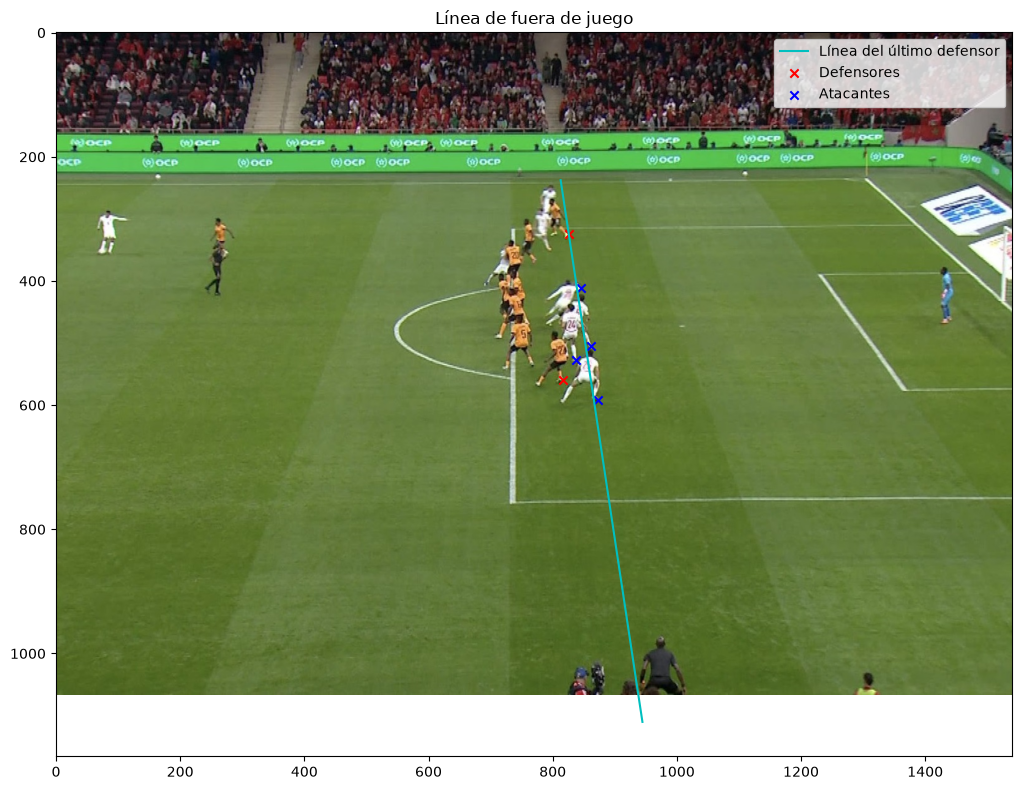

In [241]:
# Pies de los atacantes (jugadores de blanco)
atacantes = np.array([[873, 592], [838, 528], [862, 505], [845, 412]], dtype=float)

# Transformamos los atacantes a coordenadas de cancha
UV_at = alc.imagen_a_cancha(H_offside, atacantes)

print("\nPosiciones y clasificación de los atacantes:")

for i in range(len(UV_at)):

    diferencia = UV_at[i, 0] - U1

    if diferencia > 0:
        estado = "Por delante de la línea (offside)"
    else:
        estado = "Detrás de la línea (habilitado)"

    print(
        "Atacante", i + 1,
        "- Posición:", UV_at[i],
        "- Diferencia en U:", diferencia,
        "- Estado:", estado
    )

# Visualización sobre la fotografía
ruta_offside = os.path.join("futbol", "test-fuera-de-juego.png")
img_offside = mpimg.imread(ruta_offside)
plt.figure(figsize=(12, 8))
plt.imshow(img_offside)

plt.plot(recta_img[:, 0], recta_img[:, 1],'c', label='Línea del último defensor')

plt.scatter(defensores[:, 0], defensores[:, 1], color='red', marker='x', label='Defensores')

plt.scatter(atacantes[:, 0], atacantes[:, 1], color='blue', marker='x', label='Atacantes')

plt.title("Línea de fuera de juego")
plt.legend()
plt.tight_layout()
plt.show()

### Ejercicio 5: Cruzando en rojo & Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

#### Solución
##### Cálculo de parámetros intrinsecos


Para calcular los parámetros intrínsecos contamos con `world_img_pts.csv`: 5 puntos de la calle con sus coordenadas $(X, Y, Z)$ en metros y su posición $(u_j, v_j)$ en cada una de las 4 vistas.

En primer lugar, comparamos estos puntos con los 51 de `gs_10_09_point_correspondences_v5.txt`. Los píxeles de la vista 0 coinciden con puntos del v5 a menos de 3 px, pero 4 de los 5 tienen otras coordenadas en el mundo. Por ejemplo, el píxel $(418, 385)$ es $(-5, 14)$ en el CSV y $(-6, 14)$ en el v5. Como el v5 es el archivo que se usa en el inciso b), tomamos sus coordenadas.

Al haber elegido puntos sobre la calle, todos los puntos deberían quedar en el "plano" de la calle y cada vista se relaciona con él mediante una homografía:

$$
\lambda
\begin{pmatrix} u\\ v\\ 1 \end{pmatrix}
=
H_j
\begin{pmatrix} X\\ Y\\ 1 \end{pmatrix},
\qquad
H_j \sim K\,[r_1\ r_2\ t_j].
$$

Estimamos cada $H_j$ con `obtenerQ2d` y `resolverDLT2D`, como en el ejercicio 3.

In [242]:
# Datos de calibración y homografías de cada vista

np.set_printoptions(precision=2, suppress=True)

vistas = pd.read_csv("salguero/world_img_pts.csv", sep=";")
cantVistas = 4
cantPuntos = len(vistas)

datosV5 = np.loadtxt("salguero/gs_10_09_point_correspondences_v5.txt")
mundoV5 = alc.transpuesta(datosV5[1:3, :])
pixelesV5 = alc.transpuesta(datosV5[4:6, :])

# Tomamos las coordenadas del punto del v5 con el píxel más cercano en la vista 0
mundoCsv = np.asarray(vistas[["X", "Y"]], dtype=float)
pixelesVista0 = np.asarray(vistas[["u_0", "v_0"]], dtype=float)
mundo = np.zeros((cantPuntos, 2))

for i in range(cantPuntos):
    masCercano = 0
    for k in range(len(pixelesV5)):
        if alc.norma(pixelesV5[k] - pixelesVista0[i], 2) < alc.norma(pixelesV5[masCercano] - pixelesVista0[i], 2):
            masCercano = k
    mundo[i] = mundoV5[masCercano]
    distancia = alc.norma(pixelesV5[masCercano] - pixelesVista0[i], 2)
    print("Punto", i, "- CSV:", mundoCsv[i], "-> v5:", mundo[i], "(a %.1f px)" % distancia)

# Estimamos la homografía de cada vista
Hs = []
for j in range(cantVistas):
    pixelesVista = np.asarray(vistas[["u_" + str(j), "v_" + str(j)]], dtype=float)
    Hs.append(alc.resolverDLT2D(alc.obtenerQ2d(pixelesVista, mundo)))


Punto 0 - CSV: [-4.  3.] -> v5: [-4.  3.] (a 1.0 px)
Punto 1 - CSV: [4. 0.] -> v5: [4.5 0. ] (a 2.0 px)
Punto 2 - CSV: [6.5 3. ] -> v5: [7.2 2.8] (a 2.2 px)
Punto 3 - CSV: [-5. 14.] -> v5: [-6. 14.] (a 0.0 px)
Punto 4 - CSV: [-5. 76.] -> v5: [-6. 76.] (a 0.0 px)


Si aplicamos el método del ejercicio 3 (`armarA` y `calcularMatrizK2D`), obtenemos un $K$ $raro$ (entendemos que esto surge de una "limitación" de Zhang, donde requiere imágenes en distintos ángulos, salvo que hagamos lo de abajo). La sección 2.2 del enunciado afirma que si $\gamma = K_{12} = 0$, $K$ se restringe a 4 parámetros.

Nuestra siguiente idea fue probar $\alpha_u = \alpha_v$, que según el enunciado suelen cumplirse en la práctica (sección 2.1, DLT en 3D), junto a $\gamma = K_{12} = 0$. Recordemos que K era:

$$
K =
\begin{pmatrix}
\alpha_u & 0 & u_0\\
0 & \alpha_v & v_0\\
0 & 0 & 1
\end{pmatrix},
\qquad
$$

Si medimos los píxeles desde el "centro de la imagen", podemos considerar $(u_0, v_0) = 0$. Obtenemos las dimensiones de la imagen y las usamos de referencia en el código. Y utilizamos:
$$
K_c =
\begin{pmatrix}
\alpha & 0 & 0\\
0 & \alpha & 0\\
0 & 0 & 1
\end{pmatrix}.
$$

Siguiendo el paso c) de la sección 2.2 del enunciado, definimos la matriz simétrica $B = K_c^{-T}K_c^{-1}$. Como $K_c$ es diagonal, su inversa es:

$$
K_c^{-1} = K_c^{-T} =
\begin{pmatrix}
1/\alpha & 0 & 0\\
0 & 1/\alpha & 0\\
0 & 0 & 1
\end{pmatrix},
$$

y, como el producto de matrices diagonales es diagonal,

$$
B = K_c^{-T}K_c^{-1} =
\begin{pmatrix}
1/\alpha^2 & 0 & 0\\
0 & 1/\alpha^2 & 0\\
0 & 0 & 1
\end{pmatrix}.
$$

Las ecuaciones (13) del enunciado, $c_1^T B\, c_1 - c_2^T B\, c_2 = 0$ y $c_1^T B\, c_2 = 0$, están igualadas a cero, por lo que siguen valiendo si multiplicamos $B$ por $\alpha^2 \neq 0$. Podemos usar entonces

$$
\alpha^2 B =
\begin{pmatrix}
1 & 0 & 0\\
0 & 1 & 0\\
0 & 0 & \alpha^2
\end{pmatrix}
= \operatorname{diag}(1, 1, \alpha^2),
$$

donde la única incógnita es $\alpha$.
Recordemos que, según el paso b) de la sección 2.2 del enunciado, escribimos la homografía de cada vista por columnas,

$$
H = \begin{pmatrix} c_1 & c_2 & c_3 \end{pmatrix},
\qquad
c_1 = s\,K r_1,
\qquad
c_2 = s\,K r_2 \quad \text{(ecuación 12)},
$$

es decir, $c_1$ y $c_2$ son las dos primeras columnas de la homografía. En nuestro caso usamos la homografía con los píxeles centrados, y escribimos sus columnas como $c_1 = (x_1, y_1, z_1)^T$ y $c_2 = (x_2, y_2, z_2)^T$. Cada una de las 4 vistas tiene su propio par $c_1$, $c_2$.

Desarrollando:
$$
c_1^T \operatorname{diag}(1, 1, \alpha^2)\, c_2
= \underbrace{x_1 x_2 + y_1 y_2}_{p} + \alpha^2\, \underbrace{z_1 z_2}_{q}
= 0.
$$

$$
c_1^T \operatorname{diag}(1, 1, \alpha^2)\, c_1 = x_1^2 + y_1^2 + \alpha^2 z_1^2,
\qquad
c_2^T \operatorname{diag}(1, 1, \alpha^2)\, c_2 = x_2^2 + y_2^2 + \alpha^2 z_2^2,
$$
Luego los restamos:

$$
(x_1^2 + y_1^2 + \alpha^2 z_1^2) - (x_2^2 + y_2^2 + \alpha^2 z_2^2) = 0,
$$

$$
\underbrace{(x_1^2 + y_1^2 - x_2^2 - y_2^2)}_{p} + \alpha^2\, \underbrace{(z_1^2 - z_2^2)}_{q} = 0.
$$

Cada vista aporta dos ecuaciones de la forma $p + \alpha^2 q = 0$. Dividiendo por $\alpha^2$ y llamando $y = 1/\alpha^2$, cada una queda $p_k\, y + q_k = 0$. Guardamos los coeficientes de las 8 ecuaciones de las 4 vistas en dos vectores $p, q \in \mathbb{R}^8$, de modo que queda el sistema

$$
\begin{pmatrix} p_0 \\ p_1 \\ \vdots \\ p_7 \end{pmatrix} y
+
\begin{pmatrix} q_0 \\ q_1 \\ \vdots \\ q_7 \end{pmatrix}
=
\begin{pmatrix} 0 \\ 0 \\ \vdots \\ 0 \end{pmatrix},
$$

donde las posiciones $2j$ y $2j+1$ corresponden a las dos ecuaciones de la vista $j$. Como hay 8 ecuaciones para una sola incógnita, lo resolvemos por cuadrados mínimos:

$$
\min_{y}\ \|p\, y + q\|_2^2
\quad\Longrightarrow\quad
y = -\frac{p^T q}{\|p\|_2^2} = -\frac{\sum_k p_k q_k}{\sum_k p_k^2},
\qquad
\alpha = \frac{1}{\sqrt{y}}.
$$ 

In [243]:
# Ejercicio 5.a - Cálculo de K

# 1. Zhang sin restricciones, como en el ejercicio 3
print("K con Zhang sin restricciones:")
print(alc.calcularMatrizK2D(alc.armarA(Hs)))

# 2. Punto principal en el centro de la imagen
imagenInicial = mpimg.imread("salguero/img_10_18_47_351.jpg")
u0 = imagenInicial.shape[1] / 2
v0 = imagenInicial.shape[0] / 2
centrarPixeles = np.array([[1, 0, -u0], [0, 1, -v0], [0, 0, 1]], dtype=float)

# 3. Dos ecuaciones p + alfa^2 q = 0 por vista
p = np.zeros(2 * cantVistas)
q = np.zeros(2 * cantVistas)
for j in range(cantVistas):
    Hcentrada = alc.multiplicacion_matrices(centrarPixeles, Hs[j])
    Hcentrada = Hcentrada / alc.norma(Hcentrada.reshape(9), 2)
    c1 = Hcentrada[:, 0]
    c2 = Hcentrada[:, 1]
    # Acá tenemos las ecuaciones de arriba, los p y q:    
    p[2*j] = c1[0]*c2[0] + c1[1]*c2[1]
    q[2*j] = c1[2]*c2[2]
    p[2*j + 1] = c1[0]**2 + c1[1]**2 - c2[0]**2 - c2[1]**2
    q[2*j + 1] = c1[2]**2 - c2[2]**2

# 4. Cuadrados mínimos en la incógnita 1/alfa^2
unoSobreAlfaCuadrado = -np.sum(p * q) / np.sum(p * p)
alfa = 1 / np.sqrt(unoSobreAlfaCuadrado)

K = np.array([[alfa, 0, u0], [0, alfa, v0], [0, 0, 1]], dtype=float)
print("\nK con gamma = 0, alfa_u = alfa_v y punto principal en el centro:")
print(K)


K con Zhang sin restricciones:
[[2027.03  452.42  764.33]
 [   0.    133.8   224.74]
 [   0.      0.      1.  ]]

K con gamma = 0, alfa_u = alfa_v y punto principal en el centro:
[[2092.51    0.    800.  ]
 [   0.   2092.51  600.  ]
 [   0.      0.      1.  ]]


##### Pose de la cámara y reproyección

Con los 51 puntos de `gs_10_09_point_correspondences_v5.txt`, todos sobre la calle, estimamos por DLT la homografía $H_0$ de la imagen `img_10_18_47_351.jpg`. A continuación, con `obtenerPose2D` recuperamos $R$ y $t$ a partir de $H_0$ y la $K$ del inciso a), como en el ejercicio 3. Finalmente, reproyectamos los 51 puntos con $K\,[R \mid t]$ y medimos la distancia a los píxeles originales.

Para interpretar el error, lo comparamos con el de reproyectar usando $H_0$ directamente, que no depende de $K$ y marca el mejor resultado posible con estos datos. Obtenemos unos 20 px de error medio con $K\,[R \mid t]$, contra 7 px con $H_0$: la diferencia se debe al error de $K$.

Separado por zonas, en la senda peatonal de Salguero, donde están 37 de los 51 puntos, ambos errores son casi iguales. En la senda de Güemes y en los puntos lejanos el error con $K\,[R \mid t]$ crece y los puntos se corren siempre hacia el mismo lado.

Matriz R:
[[ 0.99  0.17  0.  ]
 [ 0.03 -0.19 -0.98]
 [-0.16  0.97 -0.2 ]]

Vector t (m):
[-3.29 -1.02 24.08]

R^T R:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]

Error de reproyección con K [R | t]: medio = 20.4 px, máximo = 104.5 px
Error de reproyección con H0:        medio = 6.7 px, máximo = 22.7 px

Error medio por zona, con K [R | t] y con H0:
Senda de Salguero: 6.8 px y 6.0 px
Senda de Güemes:   67.7 px y 10.7 px
Puntos lejanos:    27.0 px y 3.4 px


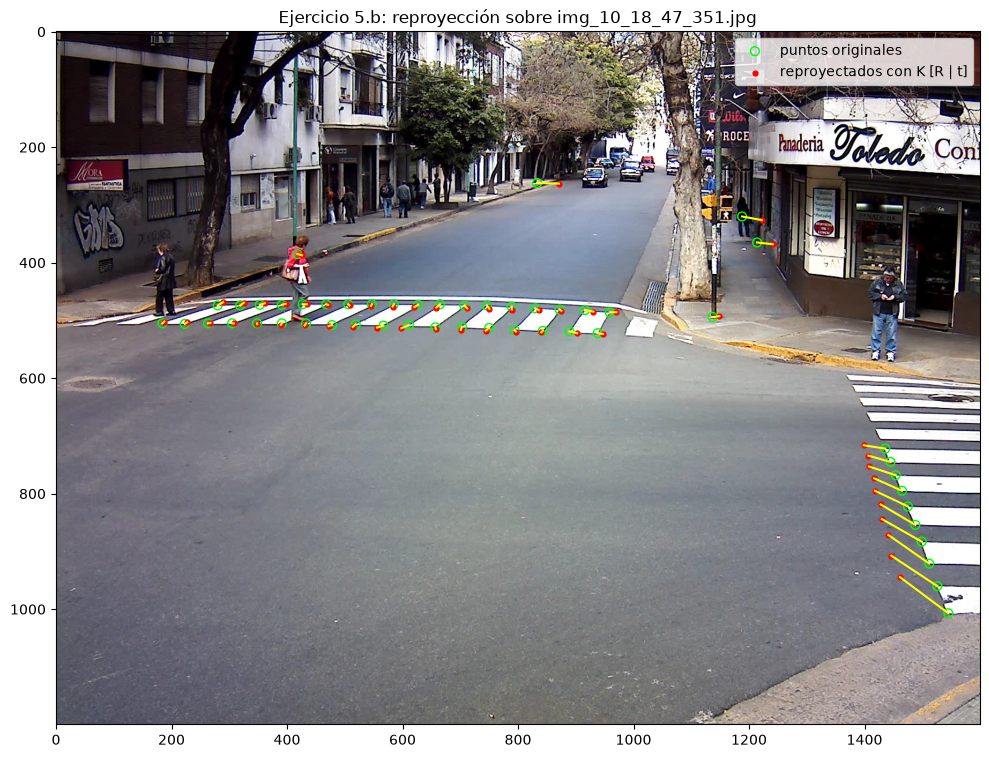

In [244]:
# Ejercicio 5.b - Pose de la cámara y reproyección sobre img_10_18_47_351.jpg

# 1. Homografía de la calle con los 51 puntos
H0 = alc.resolverDLT2D(alc.obtenerQ2d(pixelesV5, mundoV5))

# 2. Pose con la K del inciso a)
R0, t0 = alc.obtenerPose2D(H0, K)
print("Matriz R:")
print(R0)
print("\nVector t (m):")
print(t0)
print("\nR^T R:")
print(alc.multiplicacion_matrices(alc.transpuesta(R0), R0))

# 3. Matriz de proyección P0 = K [R | t]
Rt0 = np.zeros((3, 4))
Rt0[:, 0:3] = R0
Rt0[:, 3] = t0
P0 = alc.multiplicacion_matrices(K, Rt0)

# 4. Reproyección de los 51 puntos con P0 y con H0
cantPuntosV5 = len(mundoV5)
reproyectados = np.zeros((cantPuntosV5, 2))
errorConP0 = np.zeros(cantPuntosV5)
errorConH0 = np.zeros(cantPuntosV5)
for i in range(cantPuntosV5):
    proyeccionP0 = alc.matvec(P0, np.array([mundoV5[i, 0], mundoV5[i, 1], 0, 1]))
    proyeccionH0 = alc.matvec(H0, np.array([mundoV5[i, 0], mundoV5[i, 1], 1]))
    reproyectados[i] = proyeccionP0[:2] / proyeccionP0[2]
    errorConP0[i] = alc.norma(reproyectados[i] - pixelesV5[i], 2)
    errorConH0[i] = alc.norma(proyeccionH0[:2] / proyeccionH0[2] - pixelesV5[i], 2)

print("\nError de reproyección con K [R | t]: medio = %.1f px, máximo = %.1f px" % (np.mean(errorConP0), np.max(errorConP0)))
print("Error de reproyección con H0:        medio = %.1f px, máximo = %.1f px" % (np.mean(errorConH0), np.max(errorConH0)))

# 5. Error medio por zona de la calle
Y = mundoV5[:, 1]
sendaSalguero = (Y >= 0) * (Y <= 3)
sendaGuemes = Y < 0
puntosLejanos = Y > 3
print("\nError medio por zona, con K [R | t] y con H0:")
print("Senda de Salguero: %.1f px y %.1f px" % (np.mean(errorConP0[sendaSalguero]), np.mean(errorConH0[sendaSalguero])))
print("Senda de Güemes:   %.1f px y %.1f px" % (np.mean(errorConP0[sendaGuemes]), np.mean(errorConH0[sendaGuemes])))
print("Puntos lejanos:    %.1f px y %.1f px" % (np.mean(errorConP0[puntosLejanos]), np.mean(errorConH0[puntosLejanos])))

# 6. Gráfico de la reproyección
plt.figure(figsize=(12, 9))
plt.imshow(imagenInicial)
for i in range(cantPuntosV5):
    plt.plot([pixelesV5[i, 0], reproyectados[i, 0]], [pixelesV5[i, 1], reproyectados[i, 1]], color="yellow")
plt.scatter(pixelesV5[:, 0], pixelesV5[:, 1], s=40, facecolors="none", edgecolors="lime", label="puntos originales")
plt.scatter(reproyectados[:, 0], reproyectados[:, 1], s=12, color="red", label="reproyectados con K [R | t]")
plt.legend()
plt.title("Ejercicio 5.b: reproyección sobre img_10_18_47_351.jpg")
plt.show()


##### Posiciones sobre la calle y velocidades

Como la cámara no se mueve durante el video, todas las capturas comparten la $K$ del inciso a) y la pose del inciso b). Para los puntos de la calle la proyección se reduce a una homografía:

$$
\lambda
\begin{pmatrix} u\\ v\\ 1 \end{pmatrix}
=
K\,[r_1\ r_2\ t]
\begin{pmatrix} X\\ Y\\ 1 \end{pmatrix}
=
H
\begin{pmatrix} X\\ Y\\ 1 \end{pmatrix}.
$$

Con $H^{-1}$ llevamos cualquier píxel de la calle a metros.

Las posiciones de los agentes dinámicos de la escena (el taxi, la camioneta y la señora) las tomamos a mano con el script auxiliar `marcar_salguero.py`. Marcamos a cada uno en 16 de las 46 capturas (una de cada tres en orden temporal, incluyendo la primera y la última), y el script guarda los píxeles en `salguero/marcados.csv`, con una fila por captura y agente y las columnas `imagen`, `t`, `agente`, `u` y `v`.

En todas las capturas marcamos el mismo punto físico, siempre apoyado en el piso para valga $Z \approx 0$: en los autos, donde toca el piso la rueda delantera que se ve a la izquierda de la imagen, y en la señora, el punto del piso entre sus dos pies.

Con las posiciones sobre la calle calculamos la velocidad cuadro a cuadro, dividiendo la distancia recorrida entre dos capturas por el tiempo transcurrido. Como resumen, ajustamos por cuadrados mínimos una recta a $X(t)$ y otra a $Y(t)$: la velocidad es la norma del vector formado por sus dos pendientes. Como control, repetimos el cálculo con $H_0$, que no depende de $K$.

In [245]:
# Ejercicio 5.c - Posiciones sobre la calle y velocidades

# 1. Homografía de la calle: H = K [r1 r2 t]
Hcalle = np.zeros((3, 3))
Hcalle[:, 0] = P0[:, 0]
Hcalle[:, 1] = P0[:, 1]
Hcalle[:, 2] = P0[:, 3]
HcalleInversa = alc.matriz_inversa(Hcalle)
H0inversa = alc.matriz_inversa(H0)

# 2. Píxeles marcados de cada agente
marcados = pd.read_csv("salguero/marcados.csv")
agentes = ["taxi", "camioneta", "senora"]
tiempos = {}
posiciones = {}
velocidadesCuadro = {}
velocidadesCM = {}

for agente in agentes:
    marcasAgente = marcados[marcados["agente"] == agente]
    t = np.asarray(marcasAgente["t"], dtype=float)
    t = t - t[0]
    pixeles = np.asarray(marcasAgente[["u", "v"]], dtype=float)

    # 3. Posiciones sobre la calle, con H y con H0
    P = np.zeros((len(t), 2))
    P_H0 = np.zeros((len(t), 2))
    for k in range(len(t)):
        P[k] = alc.imagenACalle(HcalleInversa, pixeles[k])
        P_H0[k] = alc.imagenACalle(H0inversa, pixeles[k])

    # 4. Velocidad cuadro a cuadro y por cuadrados mínimos
    desplazamientos = np.diff(P, axis=0)
    intervalos = np.diff(t)
    vCuadro = np.zeros(len(intervalos))
    for k in range(len(intervalos)):
        vCuadro[k] = alc.norma(desplazamientos[k], 2) / intervalos[k]

    vCM = np.sqrt(alc.pendienteCuadradosMinimos(t, P[:, 0])**2 + alc.pendienteCuadradosMinimos(t, P[:, 1])**2)
    vCM_H0 = np.sqrt(alc.pendienteCuadradosMinimos(t, P_H0[:, 0])**2 + alc.pendienteCuadradosMinimos(t, P_H0[:, 1])**2)

    tiempos[agente] = t
    posiciones[agente] = P
    velocidadesCuadro[agente] = vCuadro
    velocidadesCM[agente] = vCM

    print(agente + ":")
    print("  velocidad cuadro a cuadro (km/h):", vCuadro * 3.6)
    print("  velocidad por cuadrados mínimos: %.1f km/h (control con H0: %.1f km/h)" % (vCM * 3.6, vCM_H0 * 3.6))


taxi:
  velocidad cuadro a cuadro (km/h): [43.38 49.2  41.06 37.47 41.76 69.4  68.66 49.53 63.27 48.3  48.11 50.08
 49.32 50.43 42.12]
  velocidad por cuadrados mínimos: 50.7 km/h (control con H0: 48.8 km/h)
camioneta:
  velocidad cuadro a cuadro (km/h): [55.66 32.82 46.5  39.49 40.09 79.39 62.4  64.27 48.42 53.88 51.08 62.44
 54.89 55.1  46.98]
  velocidad por cuadrados mínimos: 53.0 km/h (control con H0: 50.9 km/h)
senora:
  velocidad cuadro a cuadro (km/h): [6.88 7.3  1.03 6.36 6.44 5.36 4.37 6.53 5.79 2.75 4.7  3.74 6.96 3.84
 1.9 ]
  velocidad por cuadrados mínimos: 4.9 km/h (control con H0: 4.9 km/h)


##### Trayectorias y velocidad en el tiempo

En la top view, los autos avanzan por Salguero (eje $Y$) y la señora cruza por la senda peatonal (eje $X$), como se espera.

La velocidad cuadro a cuadro oscila por el error de marcado. Además, los dos autos tienen un pico en el mismo intervalo, entre $t \approx 1.9$ s y $t \approx 2.5$ s. Como los marcamos por separado, el pico no puede venir del marcado; justo ahí los $\Delta t$ entre capturas son irregulares (0.47, 0.47, 0.30 y 0.30 s, contra unos 0.33 s en el resto), lo que sugiere un error en el instante registrado de alguna captura. La recta de cuadrados mínimos casi no se ve afectada porque usa todas las capturas a la vez.

Obtenemos unos 51 km/h para el taxi, 53 km/h para la camioneta y 4.9 km/h para la señora . El control con $H_0$ da unos 2 km/h menos para los autos y lo mismo para la señora: el error de $K$ se nota lejos de la senda peatonal.

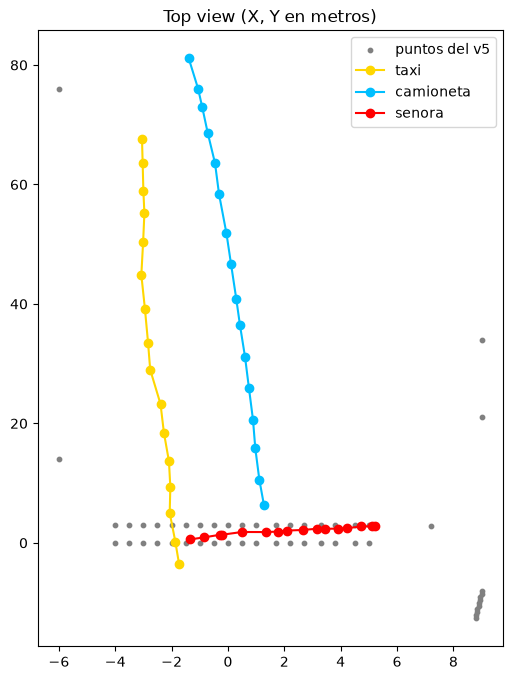

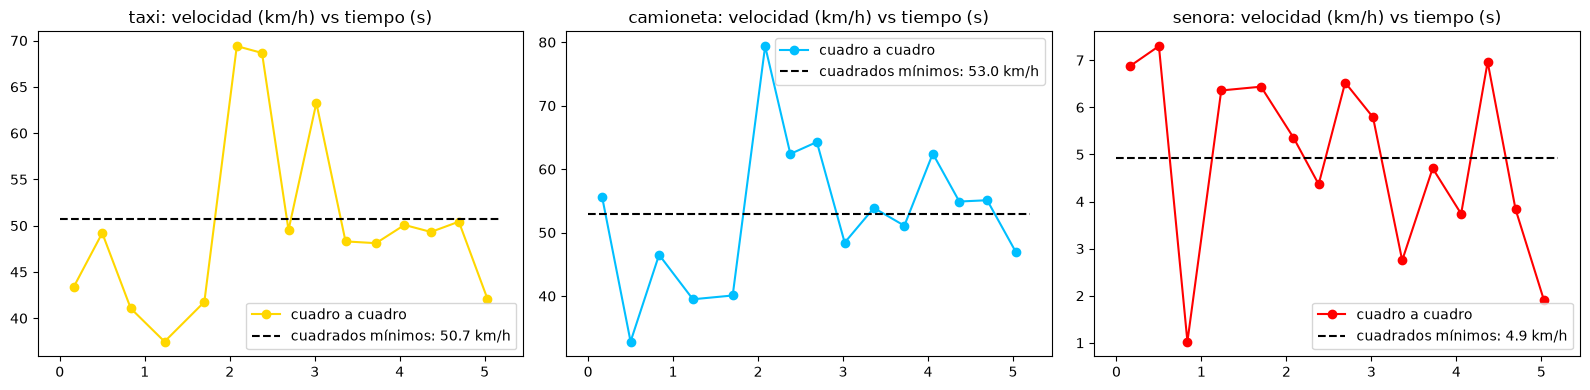

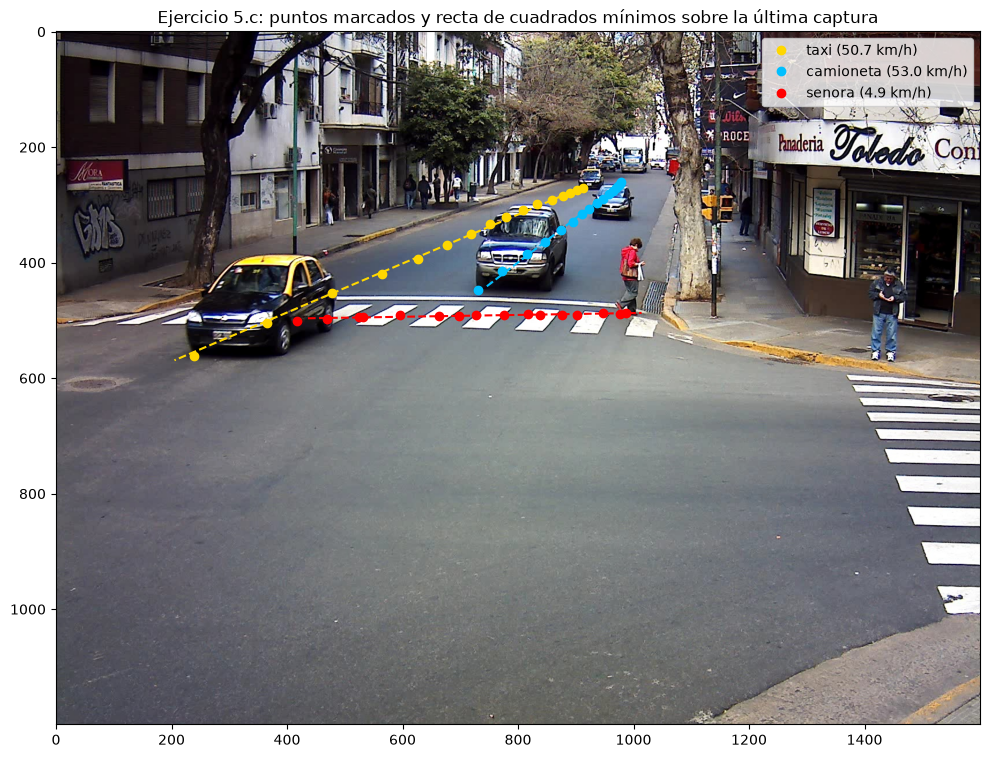

In [246]:
# Ejercicio 5.c - Trayectorias y velocidad en el tiempo
colores = {"taxi": "gold", "camioneta": "deepskyblue", "senora": "red"}

# 1. Trayectorias en vista de planta
plt.figure(figsize=(6, 8))
plt.scatter(mundoV5[:, 0], mundoV5[:, 1], s=10, color="gray", label="puntos del v5")
for agente in agentes:
    plt.plot(posiciones[agente][:, 0], posiciones[agente][:, 1], "o-", color=colores[agente], label=agente)
plt.legend()
plt.title("Top view (X, Y en metros)")
plt.show()

# 2. Velocidad en función del tiempo
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for i in range(len(agentes)):
    agente = agentes[i]
    t = tiempos[agente]
    instantesMedios = (t[:-1] + t[1:]) / 2
    vCM = velocidadesCM[agente] * 3.6
    axs[i].plot(instantesMedios, velocidadesCuadro[agente] * 3.6, "o-", color=colores[agente], label="cuadro a cuadro")
    axs[i].plot([0, t[-1]], [vCM, vCM], "k--", label="cuadrados mínimos: %.1f km/h" % vCM)
    axs[i].set_title(agente + ": velocidad (km/h) vs tiempo (s)")
    axs[i].legend()
plt.tight_layout()
plt.show()


imagenFinal = mpimg.imread("salguero/gs_dataset/img_10_18_52_546.jpg")

plt.figure(figsize=(12, 9))
plt.imshow(imagenFinal)
for agente in agentes:
    marcasAgente = marcados[marcados["agente"] == agente]
    pixeles = np.asarray(marcasAgente[["u", "v"]], dtype=float)
    t = tiempos[agente]
    P = posiciones[agente]

    pendienteX = alc.pendienteCuadradosMinimos(t, P[:, 0])
    pendienteY = alc.pendienteCuadradosMinimos(t, P[:, 1])
    rectaEnImagen = np.zeros((len(t), 2))
    for k in range(len(t)):
        X = np.mean(P[:, 0]) + pendienteX * (t[k] - np.mean(t))
        Y = np.mean(P[:, 1]) + pendienteY * (t[k] - np.mean(t))
        rectaEnImagen[k] = alc.calleAImagen(Hcalle, X, Y)

    plt.plot(pixeles[:, 0], pixeles[:, 1], "o", color=colores[agente],
             label=agente + " (%.1f km/h)" % (velocidadesCM[agente] * 3.6))
    plt.plot(rectaEnImagen[:, 0], rectaEnImagen[:, 1], "--", color=colores[agente])
plt.legend()
plt.title("Ejercicio 5.c: puntos marcados y recta de cuadrados mínimos sobre la última captura")
plt.show()


### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

#### Solución
##### Estimación de la pose mediante POSIT

Para estimar la pose de la cámara a partir de la imagen `row_00248.png`, utilizamos el algoritmo **POSIT para puntos coplanares** presentado en el enunciado. Tenemos en cuenta cinco correspondencias entre posiciones conocidas del mundo y sus coordenadas en la imagen: el centro de la H y sus cuatro extremos. El punto blanco permite identificar cuál es la esquina superior izquierda en el sistema de referencia de la H.

Los puntos tridimensionales se encuentran en el plano $W=0$ y se expresan en metros. La matriz intrínseca $K$ se obtiene de `heli/K.csv`. Como las distancias focales $f_x$ y $f_y$ son diferentes, la implementación reescala la coordenada vertical para trabajar con una focal común.

En cada iteración, POSIT resuelve los sistemas lineales del método POS, construye dos poses candidatas a partir de $I_0\pm\lambda n$ y $J_0\pm\mu n$, y selecciona la pose que proyecta todos los puntos delante de la cámara y presenta menor error RMS. Las iteraciones se detienen cuando la mejora del RMS es menor que la tolerancia indicada.

Verificamos la pose recuperada mediante la ortogonalidad de $R$ y el error de reproyección de los puntos observados.

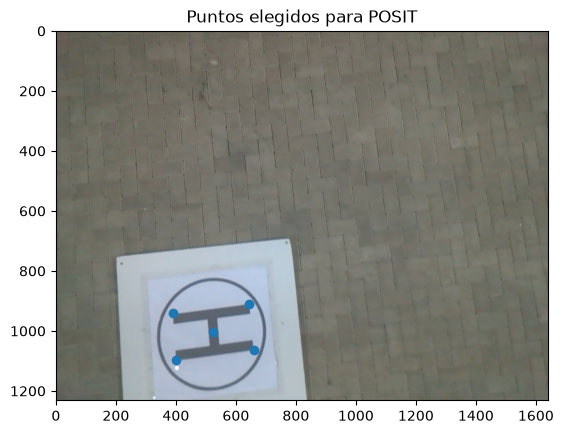

Rotación actual R:
[[-0.12 -0.96  0.27]
 [-0.98  0.07 -0.18]
 [ 0.16 -0.29 -0.95]]

Traslación actual t (m):
[-0.69  0.89  4.41]

Puntos válidos: 5 de 5
Error RMS (píxeles): 1.6437558546382887

R^T R:
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]


In [247]:
# Ejercicio 6.a - Aplicación de POSIT a los puntos de la H
ruta_heli = "heli"

# Datos tridimensionales: columnas U, V, W de object_points.csv (en metros)
objPts_dron = np.loadtxt(os.path.join(ruta_heli, "object_points.csv"), delimiter=";", skiprows=1, usecols=(1, 2, 3))

# Coordenadas observadas en row_00248.png, en el mismo orden que objPts_dron
imgPts_dron = np.array([
    [524, 1002],  # centro de la H
    [400, 1097],  # superior izquierda: punto blanco
    [389,  941],  # superior derecha
    [644,  911],  # inferior derecha
    [660, 1062]   # inferior izquierda
], dtype=float)

K_dron = np.loadtxt(os.path.join(ruta_heli, "K.csv"), delimiter=";")

# Visualización de las correspondencias elegidas
imagen_dron = mpimg.imread(os.path.join(ruta_heli, "row_00248.png"))
plt.figure()
plt.imshow(imagen_dron)
plt.scatter(imgPts_dron[:, 0], imgPts_dron[:, 1])
plt.title("Puntos elegidos para POSIT")
plt.show()

# Estimamos la pose actual
pose_dron = alc.aplicarPOSIT(objPts_dron, imgPts_dron, K_dron, MaxIt=50, atol=1e-4)
if pose_dron is None:
    raise ValueError("POSIT no encontró una pose válida para las correspondencias dadas")
R_dron, t_dron = pose_dron

validas_dron, rms_dron = alc.evaluarPose(R_dron, t_dron, objPts_dron, imgPts_dron, K_dron)

print("Rotación actual R:")
print(R_dron)
print("\nTraslación actual t (m):")
print(t_dron)
print("\nPuntos válidos:", validas_dron, "de", len(objPts_dron))
print("Error RMS (píxeles):", rms_dron)
print("\nR^T R:")
print(alc.multiplicacion_matrices(alc.transpuesta(R_dron), R_dron))


##### Pose deseada para ubicarse sobre la H

Buscamos una pose en la que la cámara quede exactamente encima del centro de la H y su eje óptico sea perpendicular al plano de aterrizaje. Conservamos la altura estimada en el inciso anterior y elegimos la orientación de modo que el punto blanco se proyecte **arriba a la izquierda** de la imagen.

Del modelo de cámara utilizado en la ecuación (15) del enunciado,

$$
P_c=RP_w+t,
$$

obtenemos la posición $C$ del centro de cámara en coordenadas del mundo al imponer $P_c=0$:

$$
C=-R^Tt.
$$

Como la H se encuentra en $W=0$, la altura de la cámara corresponde a la tercera componente $C_3$, **no necesariamente a $t_3$**. La posición y orientación deseadas son

$$
C_{\mathrm{des}}=(0,0,C_3)^T, \qquad
R_{\mathrm{des}}=\begin{pmatrix}1&0&0\\0&-1&0\\0&0&-1\end{pmatrix}.
$$

La traslación de la nueva pose se calcula mediante $t_{\mathrm{des}}=-R_{\mathrm{des}}C_{\mathrm{des}}$. También calculamos la rotación relativa $R_{\mathrm{des}}R^T$ y el desplazamiento del centro de cámara entre ambas posiciones.

Finalmente, reproyectamos los puntos con la pose deseada para comprobar que el centro de la H coincida con el punto principal $(c_u,c_v)$ y que la esquina marcada aparezca arriba a la izquierda. Estos resultados describen la **pose de la cámara**; para convertirlos en comandos de vuelo sería necesario conocer la posición y orientación de la cámara respecto del cuerpo del dron.

---

In [248]:
# Ejercicio 6.b - Estimación de la pose deseada

# Centro de la cámara actual en coordenadas del mundo
C_dron = -alc.matvec(alc.transpuesta(R_dron), t_dron)
altura_dron = C_dron[2]

# Cámara vertical orientada hacia el plano W = 0
R_des = np.array([
    [1.,  0.,  0.],
    [0., -1.,  0.],
    [0.,  0., -1.]
])

# Centro deseado: justo sobre el centro de la H, a la misma altura
C_des = np.array([0., 0., altura_dron])
t_des = -alc.matvec(R_des, C_des)

# Cambio de orientación y desplazamiento expresado en ejes actuales de cámara
R_corregida = alc.multiplicacion_matrices(R_des, alc.transpuesta(R_dron))
dC = C_des - C_dron
d_cam = alc.matvec(R_dron, dC)

# Comprobación mediante reproyección de los puntos del plano
imgPts_deseados = alc.reproyectar_puntos(R_des, t_des, objPts_dron, K_dron)

print("Centro de cámara actual C (m):", C_dron)
print("Altura conservada (m):", altura_dron)
print("Centro de cámara deseado C_des (m):", C_des)
print("\nRotación deseada R_des:")
print(R_des)
print("\nTraslación deseada t_des (m):", t_des)
print("\nRotación relativa R_corregida:")
print(R_corregida)
print("\nDesplazamiento en ejes actuales de cámara (m):", d_cam)
print("\nProyección del centro de la H:", imgPts_deseados[0])
print("Punto principal de K:", K_dron[0, 2], K_dron[1, 2])
print("Proyección de la esquina marcada:", imgPts_deseados[1])


Centro de cámara actual C (m): [0.11 0.54 4.52]
Altura conservada (m): 4.5230968441864565
Centro de cámara deseado C_des (m): [0.   0.   4.52]

Rotación deseada R_des:
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]]

Traslación deseada t_des (m): [-0.   -0.    4.52]

Rotación relativa R_corregida:
[[-0.12 -0.98  0.16]
 [ 0.96 -0.07  0.29]
 [-0.27  0.18  0.95]]

Desplazamiento en ejes actuales de cámara (m): [0.53 0.07 0.14]

Proyección del centro de la H: [np.float64(819.5) np.float64(615.5)]
Punto principal de K: 819.5 615.5
Proyección de la esquina marcada: [np.float64(746.2631201782102) np.float64(488.8500476037153)]
